<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
# Import packages
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn import tree, metrics
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

import matplotlib_inline.backend_inline
from pathlib import Path
import warnings
warnings.simplefilter("ignore")
LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
"Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL
data = pd.read_csv(source)
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: https://raw.githubusercontent.com/tovarrog24/Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv
Shape: (756, 19)


**1. Decision Tree Regression**


*   Build and train a Decision Tree Regressor on your dataset
*   Evaluate model perfoamnce using appropriate regression metrics (R^2, RMSE, MAE) and visualize the resulting tree structure or feature importances


*   Experiment with hyperparamter tuning (max_depth, mn_samples_split) to observe and prevent overfitting





|--- EDStations <= 27.50
|   |--- EDStations <= 13.50
|   |   |--- value: [13833.10]
|   |--- EDStations >  13.50
|   |   |--- value: [30830.63]
|--- EDStations >  27.50
|   |--- EDStations <= 52.50
|   |   |--- value: [54090.47]
|   |--- EDStations >  52.50
|   |   |--- value: [82690.43]



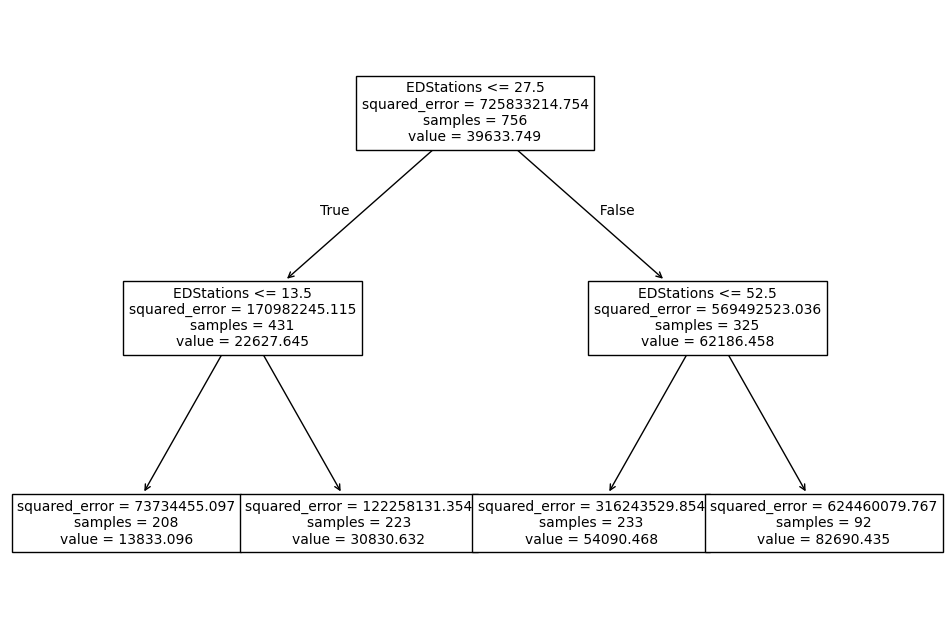

In [26]:
#Our best regression fit was the regression line when we compared ED stations to total ED visits. In essence, we are trying to predict the burden (which is calculated using these two variables)
#The number to beat is R^2 = 0.687

X = data[["EDStations"]]
y = data[["Tot_ED_NmbVsts"]]

regtreeModel = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2)
regtreeModel.fit(X, y);

print(export_text(regtreeModel, feature_names=X.columns.to_list()))

# Using tree.plot_tree() makes a cleaner figure

# Resize the plotting window
plt.figure(figsize=[12, 8])

p = tree.plot_tree(
    regtreeModel,
    feature_names=X.columns,
    class_names=y,
    filled=False,
    fontsize=10)

# Add the predictions to the original data set
data["pred"] = regtreeModel.predict(X)

229808729.8234679
R^2: 0.6833863136157791


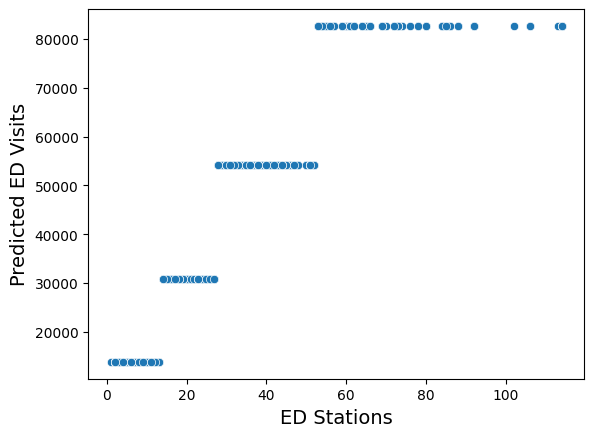

In [27]:
# Plot observed vs. predictions
p = sns.scatterplot(data=data, x="EDStations", y="pred")
p.set_xlabel("ED Stations", fontsize=14)
p.set_ylabel("Predicted ED Visits", fontsize=14)

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared = regtreeModel.score(X, y)
print("R^2:", r_squared)

This is technically very very slightly worse, but it does not hold much statistical significance. The plotting of the predicted values do show how the predicted values of the ED visits tends to vary more as you have more ED stations, just as we saw in the regression section.

In [28]:
#Figuring out the best number of leaves and splits. We use a 3D gradient vector decent for this. We will create a new dataset such that
#the primary keys are coordinates containing (min leaf, max depth) and the features will contain the MSE and the R^2. Then we plot this in
#3 space. We then use gradients of each of the points to figure out the local (and hopefully global) minimum of error. Because we are going to use
#cross-validation, we are going to avoid overfitting as much as possible. Optimization, it is what I do! We are also going to create a fun interactive
#map to mess with and see.


from sklearn.model_selection import KFold, cross_val_score
import plotly.graph_objects as go

# Hyperparameter ranges
depthValues = range(1, 21)
leafValues = range(2, 41)

# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store results
results = []

for depth in depthValues:
    for leaves in leafValues:

        model = DecisionTreeRegressor(
            max_depth=depth,
            max_leaf_nodes=leaves,
            min_samples_leaf=2,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        results.append({
            "Max_Leaves": leaves,
            "Max_Depth": depth,
            "MSE": -scores.mean()
        })

# Create results dataset
treeResults = pd.DataFrame(results)

# Find minimum error
bestRow = treeResults.loc[treeResults["MSE"].idxmin()]

print("Optimal Leaves:", int(bestRow["Max_Leaves"]))
print("Optimal Depth:", int(bestRow["Max_Depth"]))
print("Minimum CV MSE:", bestRow["MSE"])

# Convert results into a surface
surface = treeResults.pivot(
    index="Max_Depth",
    columns="Max_Leaves",
    values="MSE"
)

# Interactive 3D graph
fig = go.Figure()

fig.add_trace(go.Surface(
    x=surface.columns.to_numpy(),
    y=surface.index.to_numpy(),
    z=surface.to_numpy(),
    colorscale="Viridis"
))

fig.add_trace(go.Scatter3d(
    x=[bestRow["Max_Leaves"]],
    y=[bestRow["Max_Depth"]],
    z=[bestRow["MSE"]],
    mode="markers",
    marker=dict(size=7, color="red"),
    name="Minimum MSE"
))

fig.update_layout(
    title="Decision Tree Hyperparameter Optimization",
    scene=dict(
        xaxis_title="Maximum Leaves",
        yaxis_title="Maximum Depth",
        zaxis_title="Cross-Validation MSE"
    )
)

fig.show()


Optimal Leaves: 29
Optimal Depth: 5
Minimum CV MSE: 190325816.6996816


|--- EDStations <= 27.50
|   |--- EDStations <= 13.50
|   |   |--- EDStations <= 9.50
|   |   |   |--- EDStations <= 7.50
|   |   |   |   |--- value: [6932.00]
|   |   |   |--- EDStations >  7.50
|   |   |   |   |--- value: [11760.39]
|   |   |--- EDStations >  9.50
|   |   |   |--- EDStations <= 11.50
|   |   |   |   |--- value: [21875.86]
|   |   |   |--- EDStations >  11.50
|   |   |   |   |--- value: [18885.02]
|   |--- EDStations >  13.50
|   |   |--- EDStations <= 23.50
|   |   |   |--- EDStations <= 17.50
|   |   |   |   |--- EDStations <= 15.50
|   |   |   |   |   |--- value: [26514.24]
|   |   |   |   |--- EDStations >  15.50
|   |   |   |   |   |--- value: [26118.17]
|   |   |   |--- EDStations >  17.50
|   |   |   |   |--- EDStations <= 19.50
|   |   |   |   |   |--- value: [31971.82]
|   |   |   |   |--- EDStations >  19.50
|   |   |   |   |   |--- value: [27349.43]
|   |   |--- EDStations >  23.50
|   |   |   |--- value: [39852.74]
|--- EDStations >  27.50
|   |--- EDStati

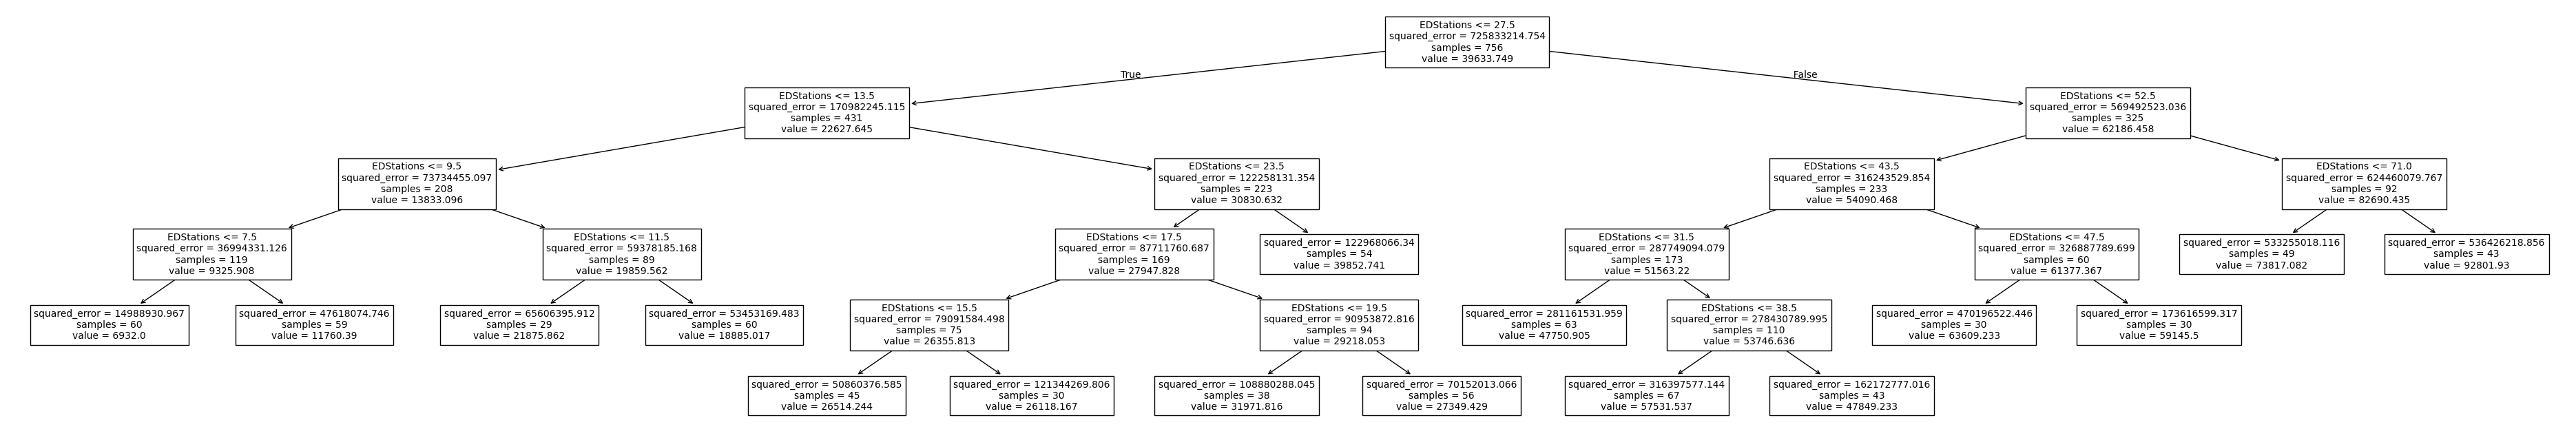

In [29]:
#Using the optimal, this is the new regression tree.

regtreeModelOptimal = DecisionTreeRegressor(max_depth=5, min_samples_leaf=29)
regtreeModelOptimal.fit(X, y);

print(export_text(regtreeModelOptimal, feature_names=X.columns.to_list()))

# Add the predictions to the original data set
data["pred"] = regtreeModelOptimal.predict(X)

plt.figure(figsize=[48, 8])

p = tree.plot_tree(
    regtreeModelOptimal,
    feature_names=X.columns,
    class_names=y,
    filled=False,
    fontsize=10)

190276881.9627368
R^2: 0.7378504068222509


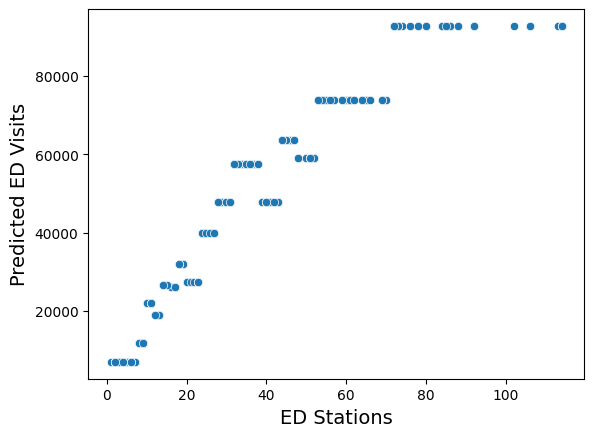

In [30]:
# Plot observed vs. predictions
p = sns.scatterplot(data=data, x="EDStations", y="pred")
p.set_xlabel("ED Stations", fontsize=14)
p.set_ylabel("Predicted ED Visits", fontsize=14)

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared = regtreeModelOptimal.score(X, y)
print("R^2:", r_squared)

This Coefficient of determination score is much higher. This means that the predicted model predicts the data more accuratley.

New starting point: 5 | Step size: 15 | MSE: 192821382.0537447
New starting point: 2 | Step size: 3 | MSE: 190325816.6996816

Optimal min_samples_split: 2
Minimum CV MSE found: 190325816.6996816


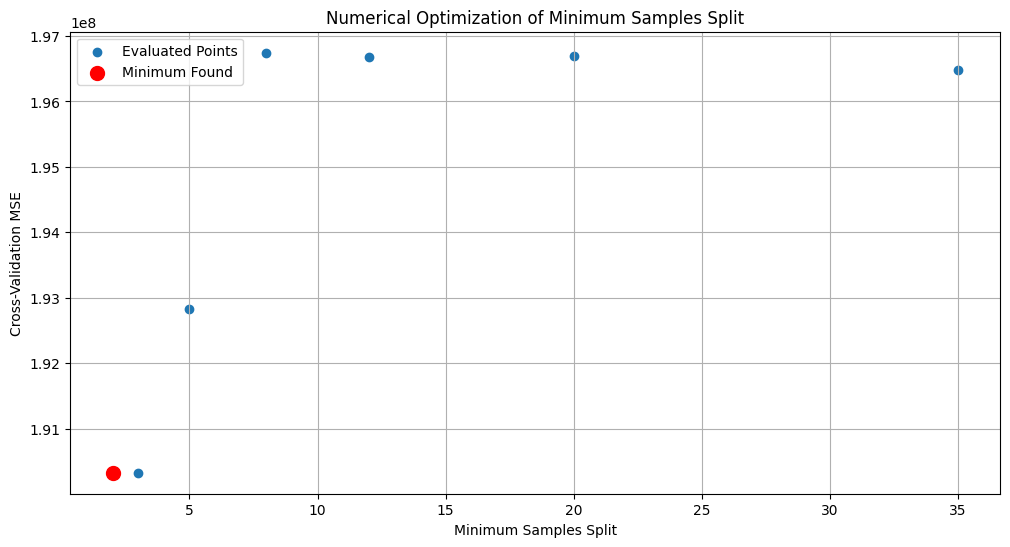

In [31]:
#To find the best min_samples_split, we use numerical methods similar to newtons method and bijections.

# Keep previously optimized hyperparameters
bestDepth = int(bestRow["Max_Depth"])
bestLeaves = int(bestRow["Max_Leaves"])

# Use the same cross-validation procedure
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store evaluated values to avoid redundant calculations
splitErrors = {}

# Define the error function
def calculateError(s):

    if s not in splitErrors:

        model = DecisionTreeRegressor(
            max_depth=bestDepth,
            max_leaf_nodes=bestLeaves,
            min_samples_leaf=2,
            min_samples_split=s,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        splitErrors[s] = -scores.mean()

    return splitErrors[s]

# Initial starting point and step size
s = 20
h = 15

# Numerical optimization
while h >= 1:

    while True:

        # Evaluate the current point and its neighbors
        candidates = [s]

        if s - h >= 2:
            candidates.append(s - h)

        if s + h <= len(X):
            candidates.append(s + h)

        # Find the candidate with the lowest error
        newS = min(candidates, key=calculateError)

        # Move only if the error strictly decreases
        if calculateError(newS) < calculateError(s):
            s = newS

            print("New starting point:", s,
                  "| Step size:", h,
                  "| MSE:", calculateError(s))

        else:
            break

    # Reduce the step size
    h = h // 2

# Final results
bestSplit = s

print("\nOptimal min_samples_split:", bestSplit)
print("Minimum CV MSE found:", calculateError(bestSplit))

# Create a dataset of evaluated points
splitResults = pd.DataFrame({
    "Min_Samples_Split": list(splitErrors.keys()),
    "MSE": list(splitErrors.values())
})

splitResults = splitResults.sort_values("Min_Samples_Split")

# Plot the evaluated points
plt.figure(figsize=(12, 6))

plt.scatter(
    splitResults["Min_Samples_Split"],
    splitResults["MSE"],
    label="Evaluated Points"
)

plt.scatter(
    bestSplit,
    calculateError(bestSplit),
    color="red",
    s=100,
    label="Minimum Found"
)

plt.xlabel("Minimum Samples Split")
plt.ylabel("Cross-Validation MSE")
plt.title("Numerical Optimization of Minimum Samples Split")
plt.legend()
plt.grid()
plt.show()


|--- EDStations <= 27.50
|   |--- EDStations <= 13.50
|   |   |--- EDStations <= 9.50
|   |   |   |--- EDStations <= 4.50
|   |   |   |   |--- EDStations <= 2.50
|   |   |   |   |   |--- value: [2071.50]
|   |   |   |   |--- EDStations >  2.50
|   |   |   |   |   |--- value: [4787.67]
|   |   |   |--- EDStations >  4.50
|   |   |   |   |--- EDStations <= 7.50
|   |   |   |   |   |--- value: [8852.24]
|   |   |   |   |--- EDStations >  7.50
|   |   |   |   |   |--- value: [11760.39]
|   |   |--- EDStations >  9.50
|   |   |   |--- EDStations <= 10.50
|   |   |   |   |--- value: [24756.80]
|   |   |   |--- EDStations >  10.50
|   |   |   |   |--- value: [18866.88]
|   |--- EDStations >  13.50
|   |   |--- EDStations <= 23.50
|   |   |   |--- EDStations <= 17.50
|   |   |   |   |--- EDStations <= 16.50
|   |   |   |   |   |--- value: [27502.73]
|   |   |   |   |--- EDStations >  16.50
|   |   |   |   |   |--- value: [16750.38]
|   |   |   |--- EDStations >  17.50
|   |   |   |   |--- EDSt

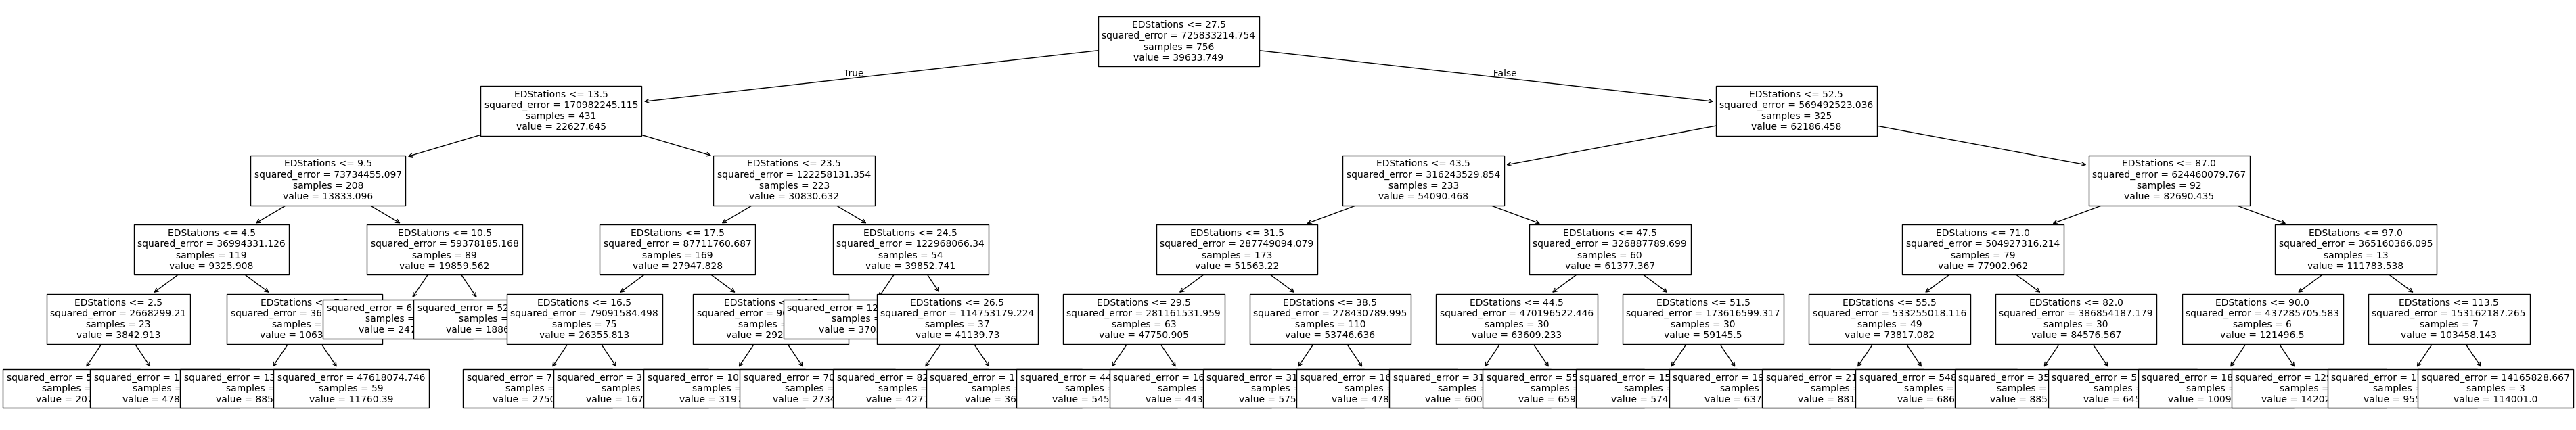

In [32]:
#New completley optimized regression tree

#Using the optimal, this is the new regression tree.

regtreeModelTotallyOptimal = DecisionTreeRegressor(max_depth=5, max_leaf_nodes=29, min_samples_split=2)
regtreeModelTotallyOptimal.fit(X, y);

print(export_text(regtreeModelTotallyOptimal, feature_names=X.columns.to_list()))

# Add the predictions to the original data set
data["pred"] = regtreeModelTotallyOptimal.predict(X)

plt.figure(figsize=[48, 8])

p = tree.plot_tree(
    regtreeModelTotallyOptimal,
    feature_names=X.columns,
    class_names=y,
    filled=False,
    fontsize=10)

162783569.747221
R^2: 0.7757286847194984


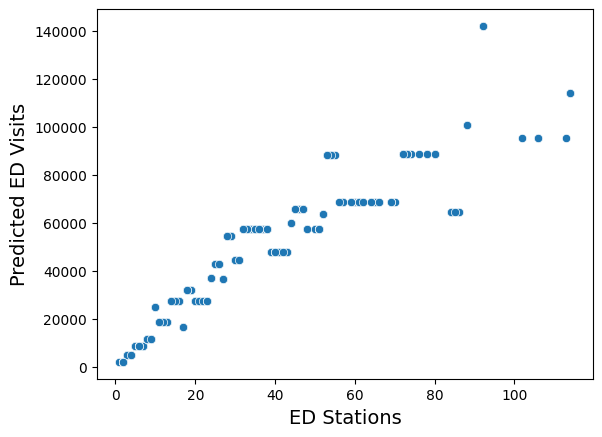

In [33]:
# Plot observed vs. predictions
p = sns.scatterplot(data=data, x="EDStations", y="pred")
p.set_xlabel("ED Stations", fontsize=14)
p.set_ylabel("Predicted ED Visits", fontsize=14)

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared = regtreeModelTotallyOptimal.score(X, y)
print("R^2:", r_squared)

In [34]:
#Calculated all the model testing variables

RMSE = root_mean_squared_error(y, data["pred"])
MAE = mean_absolute_error(y, data["pred"])

print("RMSE:", RMSE)
print("MAE:", MAE)
print("R^2", r_squared)

RMSE: 12758.666456460918
MAE: 8978.259092832785
R^2 0.7757286847194984


This is a much better model.

Limitations:
There are some limitations to our optimization methods. For the numerical methods, there is no telling if the data is actually continuous, smooth, analytical, unimodal, or convex. These are assumptions made, but such is going to happen when making somewhat naive numerical optimization methods. There do exist optimization methods that could take all of these (independently perhaps) into account, but they are NP and computationally expensive.

|--- LATITUDE <= 32.92
|   |--- LATITUDE <= 32.72
|   |   |--- value: [27.67]
|   |--- LATITUDE >  32.72
|   |   |--- value: [77.76]
|--- LATITUDE >  32.92
|   |--- LATITUDE <= 38.84
|   |   |--- value: [28.99]
|   |--- LATITUDE >  38.84
|   |   |--- value: [13.96]



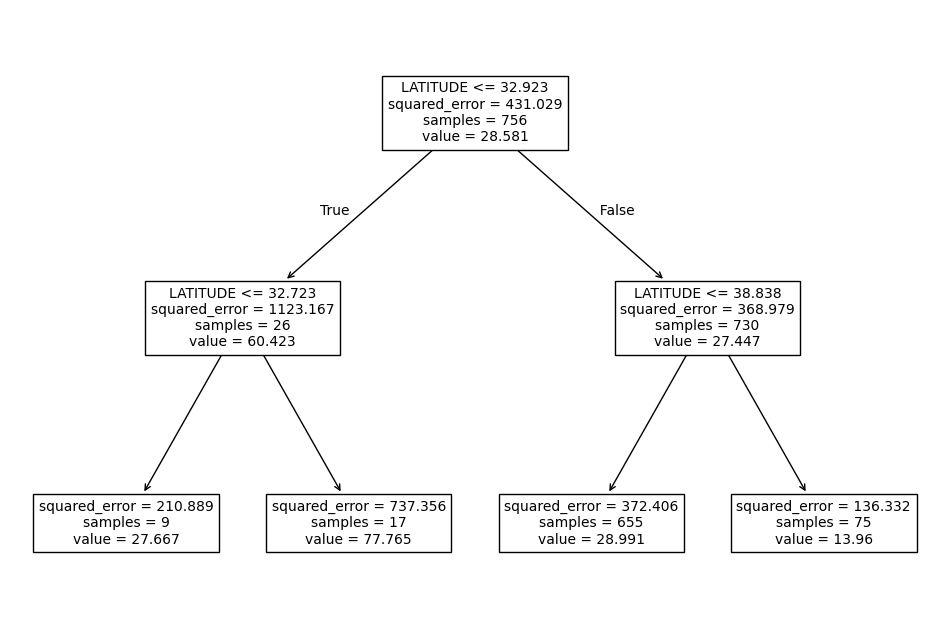

In [35]:
#Using location (Longitude and Latitide) seems to yeild better results. This may be because of the political state of the location that varies county by county.
#Using a Decision Tree Regression could be good to estimate a numerical value like ED Stations that will involve some form of location
#Though the number to beat as relativley low, the cluters themselves were helpful in the Unsupervised learning task, it is for this reason that we will try to use location again

#We will use the exact same processes as the previous task in this one without much justification since rationale can be found above.

#Our best regression fit was the regression line when we compared ED stations to total ED visits. In essence, we are trying to predict the burden (which is calculated using these two variables)
#The number to beat is R^2 = 0.687

X = data[["LONGITUDE", "LATITUDE"]]
y = data[["EDStations"]]

regtreeModel2 = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2)
regtreeModel2.fit(X, y);

print(export_text(regtreeModel2, feature_names=X.columns.to_list()))

# Using tree.plot_tree() makes a cleaner figure

# Resize the plotting window
plt.figure(figsize=[12, 8])

p = tree.plot_tree(
    regtreeModel2,
    feature_names=X.columns,
    class_names=y,
    filled=False,
    fontsize=10)

# Add the predictions to the original data set
data["pred"] = regtreeModel2.predict(X)

In [36]:
#Using a 3d plot since X has two variables
# Plot observed vs. predictions
import plotly.express as px

fig = px.scatter_3d(
    data,
    x="LONGITUDE",
    y="LATITUDE",
    z="pred",
    color="pred",
    labels={
        "LONGITUDE": "Longitude",
        "LATITUDE": "Latitude",
        "pred": "Predicted ED Stations"
    },
    title="Predicted ED Stations Based on Geographical Location"
)

fig.show()

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared2 = regtreeModel2.score(X, y)
print("R^2:", r_squared2)

355.2696876477479
R^2: 0.17576423001301478


In [37]:
from sklearn.model_selection import KFold, cross_val_score
import plotly.graph_objects as go

# Hyperparameter ranges
depthValues = range(1, 21)
leafValues = range(2, 41)

# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store results
results = []

for depth in depthValues:
    for leaves in leafValues:

        model = DecisionTreeRegressor(
            max_depth=depth,
            max_leaf_nodes=leaves,
            min_samples_leaf=2,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        results.append({
            "Max_Leaves": leaves,
            "Max_Depth": depth,
            "MSE": -scores.mean()
        })

# Create results dataset
treeResults = pd.DataFrame(results)

# Find minimum error
bestRow = treeResults.loc[treeResults["MSE"].idxmin()]

print("Optimal Leaves:", int(bestRow["Max_Leaves"]))
print("Optimal Depth:", int(bestRow["Max_Depth"]))
print("Minimum CV MSE:", bestRow["MSE"])

# Convert results into a surface
surface = treeResults.pivot(
    index="Max_Depth",
    columns="Max_Leaves",
    values="MSE"
)

# Interactive 3D graph
fig = go.Figure()

fig.add_trace(go.Surface(
    x=surface.columns.to_numpy(),
    y=surface.index.to_numpy(),
    z=surface.to_numpy(),
    colorscale="Viridis"
))

fig.add_trace(go.Scatter3d(
    x=[bestRow["Max_Leaves"]],
    y=[bestRow["Max_Depth"]],
    z=[bestRow["MSE"]],
    mode="markers",
    marker=dict(size=7, color="red"),
    name="Minimum MSE"
))

fig.update_layout(
    title="Decision Tree Hyperparameter Optimization",
    scene=dict(
        xaxis_title="Maximum Leaves",
        yaxis_title="Maximum Depth",
        zaxis_title="Cross-Validation MSE"
    )
)

fig.show()


Optimal Leaves: 40
Optimal Depth: 13
Minimum CV MSE: 247.60085937435838


New starting point: 5 | Step size: 15 | MSE: 248.77637204578906
New starting point: 2 | Step size: 3 | MSE: 247.60085937435838

Optimal min_samples_split: 2
Minimum CV MSE found: 247.60085937435838


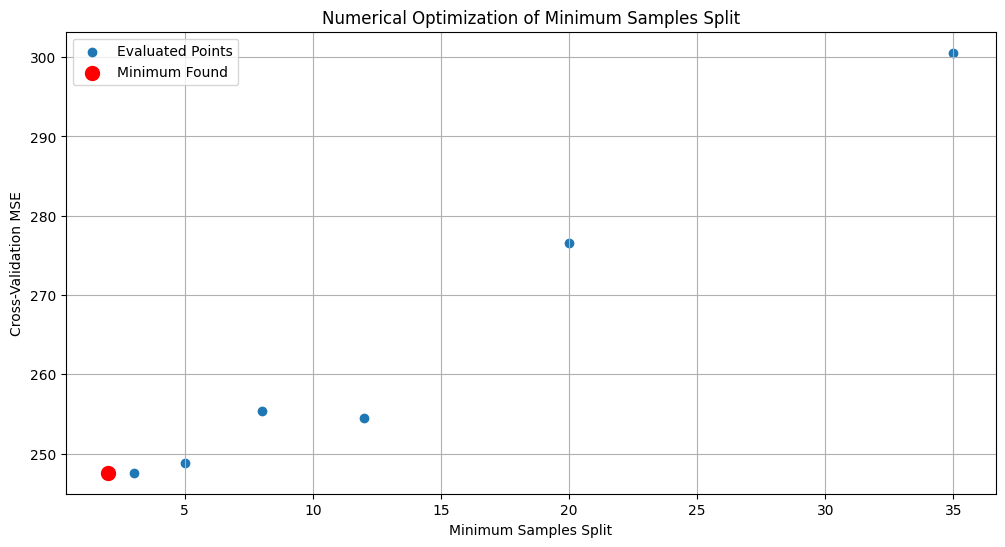

In [38]:
# Keep previously optimized hyperparameters
bestDepth = int(bestRow["Max_Depth"])
bestLeaves = int(bestRow["Max_Leaves"])

# Use the same cross-validation procedure
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store evaluated values to avoid redundant calculations
splitErrors = {}

# Define the error function
def calculateError(s):

    if s not in splitErrors:

        model = DecisionTreeRegressor(
            max_depth=bestDepth,
            max_leaf_nodes=bestLeaves,
            min_samples_leaf=2,
            min_samples_split=s,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        splitErrors[s] = -scores.mean()

    return splitErrors[s]

# Initial starting point and step size
s = 20
h = 15

# Numerical optimization
while h >= 1:

    while True:

        # Evaluate the current point and its neighbors
        candidates = [s]

        if s - h >= 2:
            candidates.append(s - h)

        if s + h <= len(X):
            candidates.append(s + h)

        # Find the candidate with the lowest error
        newS = min(candidates, key=calculateError)

        # Move only if the error strictly decreases
        if calculateError(newS) < calculateError(s):
            s = newS

            print("New starting point:", s,
                  "| Step size:", h,
                  "| MSE:", calculateError(s))

        else:
            break

    # Reduce the step size
    h = h // 2

# Final results
bestSplit = s

print("\nOptimal min_samples_split:", bestSplit)
print("Minimum CV MSE found:", calculateError(bestSplit))

# Create a dataset of evaluated points
splitResults = pd.DataFrame({
    "Min_Samples_Split": list(splitErrors.keys()),
    "MSE": list(splitErrors.values())
})

splitResults = splitResults.sort_values("Min_Samples_Split")

# Plot the evaluated points
plt.figure(figsize=(12, 6))

plt.scatter(
    splitResults["Min_Samples_Split"],
    splitResults["MSE"],
    label="Evaluated Points"
)

plt.scatter(
    bestSplit,
    calculateError(bestSplit),
    color="red",
    s=100,
    label="Minimum Found"
)

plt.xlabel("Minimum Samples Split")
plt.ylabel("Cross-Validation MSE")
plt.title("Numerical Optimization of Minimum Samples Split")
plt.legend()
plt.grid()
plt.show()


|--- LATITUDE <= 32.92
|   |--- LATITUDE <= 32.72
|   |   |--- LONGITUDE <= -117.05
|   |   |   |--- value: [17.50]
|   |   |--- LONGITUDE >  -117.05
|   |   |   |--- value: [48.00]
|   |--- LATITUDE >  32.72
|   |   |--- LATITUDE <= 32.80
|   |   |   |--- LONGITUDE <= -116.29
|   |   |   |   |--- value: [94.09]
|   |   |   |--- LONGITUDE >  -116.29
|   |   |   |   |--- value: [20.00]
|   |   |--- LATITUDE >  32.80
|   |   |   |--- value: [53.40]
|--- LATITUDE >  32.92
|   |--- LATITUDE <= 38.84
|   |   |--- LATITUDE <= 38.74
|   |   |   |--- LONGITUDE <= -117.11
|   |   |   |   |--- LATITUDE <= 33.66
|   |   |   |   |   |--- LATITUDE <= 33.62
|   |   |   |   |   |   |--- LONGITUDE <= -117.69
|   |   |   |   |   |   |   |--- value: [20.67]
|   |   |   |   |   |   |--- LONGITUDE >  -117.69
|   |   |   |   |   |   |   |--- value: [48.69]
|   |   |   |   |   |--- LATITUDE >  33.62
|   |   |   |   |   |   |--- value: [88.00]
|   |   |   |   |--- LATITUDE >  33.66
|   |   |   |   |   |--- L

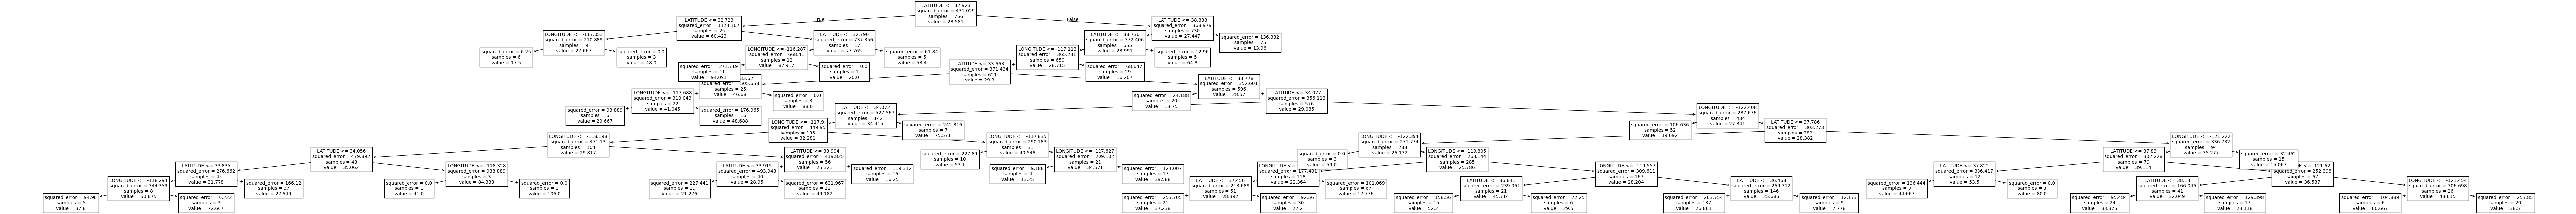

In [39]:
#New completley optimized regression tree

#Using the optimal, this is the new regression tree.

regtreeModelTotallyOptimal1 = DecisionTreeRegressor(max_depth=13, max_leaf_nodes=40, min_samples_split = 2)
regtreeModelTotallyOptimal1.fit(X, y);

print(export_text(regtreeModelTotallyOptimal1, feature_names=X.columns.to_list()))

# Add the predictions to the original data set
data["pred"] = regtreeModelTotallyOptimal1.predict(X)

plt.figure(figsize=[100, 8])

p = tree.plot_tree(
    regtreeModelTotallyOptimal1,
    feature_names=X.columns,
    class_names=y,
    filled=False,
    fontsize=10)

In [40]:
#Calculated all the model testing variables

RMSE = root_mean_squared_error(y, data["pred"])
MAE = mean_absolute_error(y, data["pred"])
r_squared = regtreeModelTotallyOptimal1.score(X, y)

print("RMSE:", RMSE)
print("MAE:", MAE)
print("R^2", r_squared)

RMSE: 12.550753269697005
MAE: 9.679388473306778
R^2 0.6345458584643116


This is a pretty good decent prediction model. It works a little over half of the time. Not the best, but not bad either. Similar limitations apply

**2. Decision Tree Classification**
* Build and train a decision tree classifier on your dataset
* Evaluate model performance using confusion matrix, accuracy, precision, and F1-score
* Visualize the decision tree splits and discuss the most influencial features driving the classifications

In [41]:
#The best logistical regression model was when we tried to predict the probability of a hospital being a teaching hospital from the station count
#It was not good, but we can try using a Decsiion tree to see if there are any improvements

Interpretation of 2

In [42]:
#In addition to ising the station count, we can use the ED Burden to predict if a hospital is a teaching hospital or not

Interpretation

In [43]:
#We can try doing the same tasks as above but partitioning the dataset to either only include urban hospitals or only include non-urban hospitals (I predict the urban ones would be better)

Interpretation

**3. Random Forest (Ensemble Learning)**
* Apply Random Forest model (classifier, Regressor, or both) to the same task(s) above
* Compare the Random Forest's perfomance, generalization, an feature importance rankings against your single Decision Tree baseline(s)

MSE:  175125574.4168326
R^2: 0.710143877543697
R^2 Trained: 0.6990983472341525
R^2 Tested: 0.7386022524385322


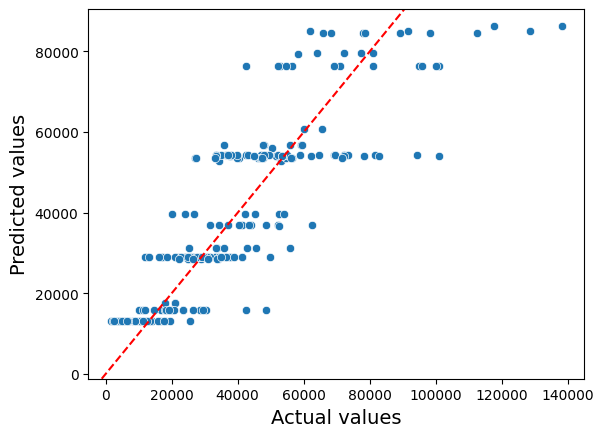

In [57]:
#Same tasks as above, just with more information and variables considered

#Regression, 1. Trying to beat the optimized regression tree with EDStations and Total ED Visits

X = data[["EDStations"]]
y = data["Tot_ED_NmbVsts"]

# Create a training/testing split
# 30% of instances held out for testing
# 70% of instances used for training
#We use random_state = 42 for the sake of reproducability
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state= 42)

# Define a regression random forest model
rfModel = RandomForestRegressor(max_depth=2, max_features="sqrt", random_state=99)

# Fit the model
rfModel.fit(X_train, y_train);

# Predict body mass on the testing data
y_pred = rfModel.predict(X_test)

# Compare testing predictions to actual values
p = sns.scatterplot(x=y_test, y=y_pred)
p.set_xlabel("Actual values", fontsize=14)
p.set_ylabel("Predicted values", fontsize=14)

# Add a diagonal line
# If the testing predictions are close to the actual values,
# points should fall along this line
plt.axline((3000, 3000), (6000, 6000), color="r", ls="--")

# Print mean squared error (MSE)
print("MSE: ", metrics.mean_squared_error(y_test, y_pred))

#R^2 calculation
r_squared = rfModel.score(X, y)
print("R^2:", r_squared)
r_squaredTrain = rfModel.score(X_train, y_train)
print("R^2 Trained:", r_squaredTrain)
r_squaredTest = rfModel.score(X_test, y_test)
print("R^2 Tested:", r_squaredTest)

Convergence achieved!
Optimal number of estimators: 2470
Final maximum difference: 62.667646916612284


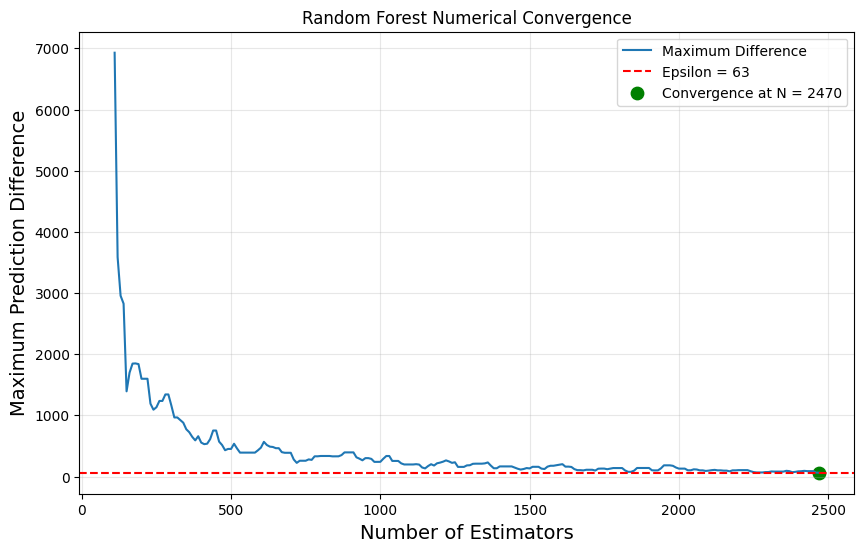

MSE: 175543425.0503585
R^2 Trained: 0.7017208900656178
R^2 Tested: 0.7379785559008647


In [62]:
#To optimize the n-estimators (the number of trees), we use a Caughy convergence sequence that is bounded by a large number.
#What this means, is that we choose a small number epsilon (100 in this case) and a large number N (5,000 in this case);
#We then create a sequence using increasing n_estimators. If the errors are all within epsilon distance from eachother, the model is good.
#To prevent overfitting, we choose the smallest n where this works, to prevent infinite runtime, we say that is n > N (5,000) then we stop and
#say that a regression forest is not a good model and that more data is needed.

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from sklearn.base import clone

# Define convergence parameters
epsilon = 63
N_max = 5000
step = 10
window = 100

# Store predictions across the convergence window
predictionWindow = deque(maxlen=window // step + 1)

# Store results for visualization
nValues = []
errorValues = []

# Initialize a separate Random Forest
rfConvergence = clone(rfModel)
rfConvergence.set_params(warm_start=True)

# Initialize convergence variables
converged = False
optimalN = None

# Incrementally construct the Random Forest
for n in range(step, N_max + 1, step):

    rfConvergence.set_params(n_estimators=n)
    rfConvergence.fit(X_train, y_train)

    # Calculate predictions
    predictions = rfConvergence.predict(X_train)
    predictionWindow.append(predictions)

    # Check whether the convergence window is full
    if len(predictionWindow) == predictionWindow.maxlen:

        # Calculate maximum pairwise prediction difference
        predictionArray = np.stack(predictionWindow)
        error = np.max(np.ptp(predictionArray, axis=0))

        # Store results
        nValues.append(n)
        errorValues.append(error)

        # Check convergence criterion
        if error < epsilon:
            optimalN = n
            converged = True
            break

# Report convergence results
if converged:
    print("Convergence achieved!")
    print("Optimal number of estimators:", optimalN)
    print("Final maximum difference:", errorValues[-1])
else:
    print("Convergence not achieved within computational bounds.")
    print("Maximum number of estimators:", N_max)
    print("Final maximum difference:", errorValues[-1])

# Visualize convergence
plt.figure(figsize=(10, 6))
plt.plot(nValues, errorValues, label="Maximum Difference")

plt.axhline(
    y=epsilon,
    color="r",
    linestyle="--",
    label=f"Epsilon = {epsilon}"
)

if converged:
    plt.scatter(
        optimalN,
        errorValues[-1],
        color="green",
        s=80,
        label=f"Convergence at N = {optimalN}"
    )

plt.xlabel("Number of Estimators", fontsize=14)
plt.ylabel("Maximum Prediction Difference", fontsize=14)
plt.title("Random Forest Numerical Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluate the resulting Random Forest
y_predConvergence = rfConvergence.predict(X_test)

print("MSE:", metrics.mean_squared_error(
    y_test, y_predConvergence
))
print("R^2 Trained:", rfConvergence.score(X_train, y_train))
print("R^2 Tested:", rfConvergence.score(X_test, y_test))

This next cell will optimize the depth of the trees. This is more difficult and requires more heavy lifting. Changing the depth of the trees is a trade-off of three other things that come with it: computational compelxity, overfitting, and underfitting. As a result of this, optimizing the depth is also optimizing all three of these things. We wish to minimize all of this, which makes this easier. Since increading d increases the leaves exponentially, we will choose a small d (10 in this case). Then, we calculate a normalize the underfitting, overfitting, and compuational error. We then sqaure all of these and add them. We then use brute force to find the smallest one and that will be our depth (d = 10, so there are only 10 options).

Depth 1 completed.
Depth 2 completed.
Depth 3 completed.
Depth 4 completed.
Depth 5 completed.
Depth 6 completed.
Depth 7 completed.
Depth 8 completed.
Depth 9 completed.
Depth 10 completed.

Optimal Maximum Depth: 3
Minimum Objective Value: 0.0358655348383559

Optimization Results:
 Depth        Error  Overfitting     Cost  Normalized_Error  Normalized_Overfitting  Normalized_Cost  Objective
     1 3.389549e+08     0.023795   7410.0          1.000000                0.000000         0.000000   1.000000
     2 2.420195e+08     0.036106  17290.0          0.165775                0.111675         0.031425   0.040940
     3 2.247243e+08     0.041805  37049.6          0.016933                0.163374         0.094274   0.035866
     4 2.232522e+08     0.058711  75564.4          0.004264                0.316733         0.216778   0.147331
     5 2.227567e+08     0.078590 136465.6          0.000000                0.497058         0.410486   0.415566
     6 2.278113e+08     0.097725 203013.6   

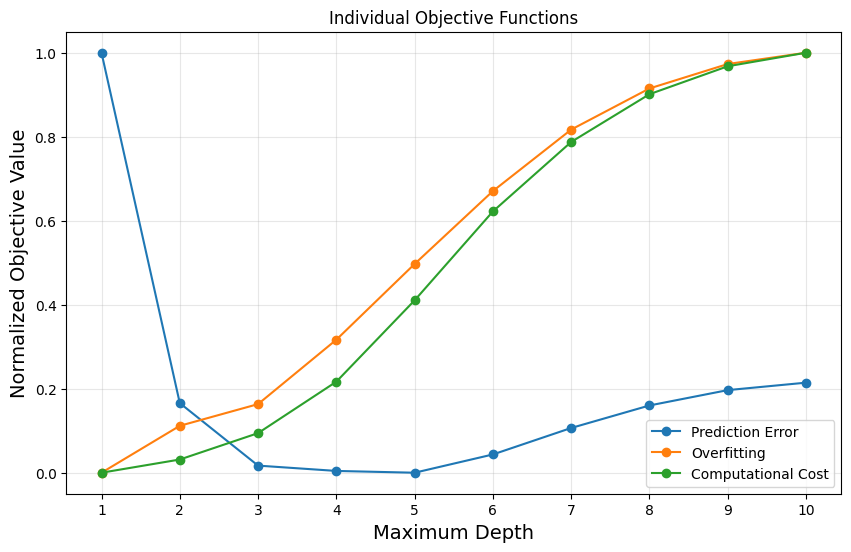

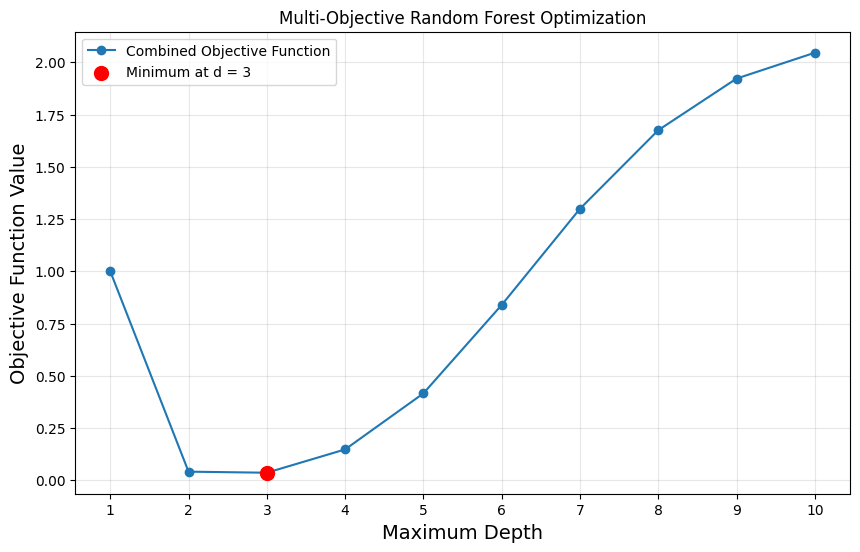


Optimized Random Forest Results:
MSE: 154895564.61864868
RMSE: 12445.704665411624
MAE: 8940.423109334277
R^2: 0.7405429472530155
R^2 Trained: 0.7295889052697612
R^2 Tested: 0.7687981790586218


In [64]:

from sklearn.model_selection import KFold, cross_validate

# Define optimization parameters
depthValues = range(1, 11)
optimalEstimators = 2470

cv = KFold(n_splits=5, shuffle=True, random_state=42)

depthResults = []

# Evaluate each possible maximum depth
for d in depthValues:

    model = clone(rfModel)
    model.set_params(
        n_estimators=optimalEstimators,
        max_depth=d,
        n_jobs=-1,
        warm_start=False
    )

    # Perform cross-validation
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        return_estimator=True,
        error_score="raise"
    )

    # Objective 1: Prediction error
    E = -np.mean(scores["test_MSE"])

    # Objective 2: Overfitting
    O = np.mean(np.maximum(
        0,
        scores["train_R2"] - scores["test_R2"]
    ))

    # Objective 3: Computational cost
    C = np.mean([
        sum(tree.tree_.node_count for tree in forest.estimators_)
        for forest in scores["estimator"]
    ])

    # Store the results
    depthResults.append({
        "Depth": d,
        "Error": E,
        "Overfitting": O,
        "Cost": C
    })

    print(f"Depth {d} completed.")

# Convert results into a DataFrame
depthResults = pd.DataFrame(depthResults)

# Min-max normalization
def normalize(values):
    minimum = values.min()
    maximum = values.max()

    if maximum == minimum:
        return values * 0

    return (values - minimum) / (maximum - minimum)

# Normalize the three objective functions
depthResults["Normalized_Error"] = normalize(
    depthResults["Error"]
)

depthResults["Normalized_Overfitting"] = normalize(
    depthResults["Overfitting"]
)

depthResults["Normalized_Cost"] = normalize(
    depthResults["Cost"]
)

# Calculate the scalar objective function
depthResults["Objective"] = (
    depthResults["Normalized_Error"] ** 2
    + depthResults["Normalized_Overfitting"] ** 2
    + depthResults["Normalized_Cost"] ** 2
)

# Find the global minimum over the evaluated depths
bestDepthRow = depthResults.loc[
    depthResults["Objective"].idxmin()
]

optimalDepth = int(bestDepthRow["Depth"])

# Display results
print("\nOptimal Maximum Depth:", optimalDepth)
print("Minimum Objective Value:", bestDepthRow["Objective"])
print("\nOptimization Results:")
print(depthResults.to_string(index=False))

# Graph the individual normalized objective functions
plt.figure(figsize=(10, 6))

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Error"],
    marker="o",
    label="Prediction Error"
)

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Overfitting"],
    marker="o",
    label="Overfitting"
)

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Cost"],
    marker="o",
    label="Computational Cost"
)

plt.xlabel("Maximum Depth", fontsize=14)
plt.ylabel("Normalized Objective Value", fontsize=14)
plt.title("Individual Objective Functions")
plt.xticks(list(depthValues))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Graph the combined objective function
plt.figure(figsize=(10, 6))

plt.plot(
    depthResults["Depth"],
    depthResults["Objective"],
    marker="o",
    label="Combined Objective Function"
)

plt.scatter(
    optimalDepth,
    bestDepthRow["Objective"],
    color="red",
    s=100,
    zorder=5,
    label=f"Minimum at d = {optimalDepth}"
)

plt.xlabel("Maximum Depth", fontsize=14)
plt.ylabel("Objective Function Value", fontsize=14)
plt.title("Multi-Objective Random Forest Optimization")
plt.xticks(list(depthValues))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Construct the optimized Random Forest
rfModelOptimal = clone(rfModel)

rfModelOptimal.set_params(
    n_estimators=optimalEstimators,
    max_depth=optimalDepth,
    n_jobs=-1,
    warm_start=False
)

rfModelOptimal.fit(X_train, y_train)

# Evaluate the optimized Random Forest
y_predOptimal = rfModelOptimal.predict(X_test)

print("\nOptimized Random Forest Results:")
print("MSE:", metrics.mean_squared_error(y_test, y_predOptimal))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_predOptimal)))
print("MAE:", metrics.mean_absolute_error(y_test, y_predOptimal))
print("R^2:", rfModelOptimal.score(X, y))
print("R^2 Trained:", rfModelOptimal.score(X_train, y_train))
print("R^2 Tested:", rfModelOptimal.score(X_test, y_test))

MSE:  154895564.61864868
R^2: 0.7405429472530155
R^2 Trained: 0.7295889052697612
R^2 Tested: 0.7687981790586217


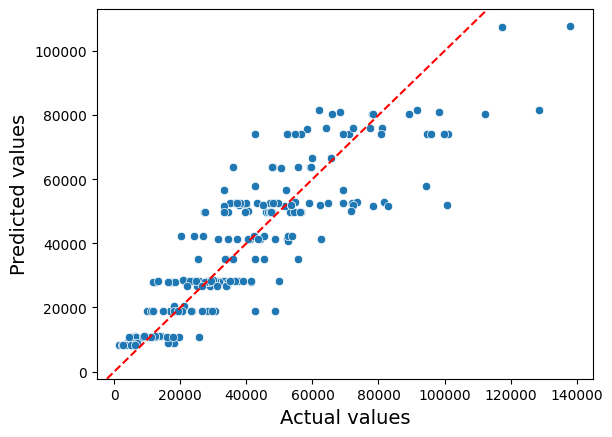

In [65]:
#Optimal forest

#Same tasks as above, just with more information and variables considered

#Regression, 1. Trying to beat the optimized regression tree with EDStations and Total ED Visits

X = data[["EDStations"]]
y = data["Tot_ED_NmbVsts"]

# Create a training/testing split
# 30% of instances held out for testing
# 70% of instances used for training
#We use random_state = 42 for the sake of reproducability
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state= 42)

# Define a regression random forest model
rfModel = RandomForestRegressor(max_depth=3, max_features="sqrt", random_state=99, n_estimators= 2470)

# Fit the model
rfModel.fit(X_train, y_train);

# Predict body mass on the testing data
y_pred = rfModel.predict(X_test)

# Compare testing predictions to actual values
p = sns.scatterplot(x=y_test, y=y_pred)
p.set_xlabel("Actual values", fontsize=14)
p.set_ylabel("Predicted values", fontsize=14)

# Add a diagonal line
# If the testing predictions are close to the actual values,
# points should fall along this line
plt.axline((3000, 3000), (6000, 6000), color="r", ls="--")

# Print mean squared error (MSE)
print("MSE: ", metrics.mean_squared_error(y_test, y_pred))

#R^2 calculation
r_squared = rfModel.score(X, y)
print("R^2:", r_squared)
r_squaredTrain = rfModel.score(X_train, y_train)
print("R^2 Trained:", r_squaredTrain)
r_squaredTest = rfModel.score(X_test, y_test)
print("R^2 Tested:", r_squaredTest)

This is higher than the R^2 score of the single tree. When optimized, this performed significanlty better. What this means, is that burden can be predicted with quite a bit of accuracy. For the sake of computational power, we will not do the geographical side of this, as that will be extremley computationally expensive since we are increasing out optimzation to include another dimention per step.